Download data:
inter-station distances in 2022
railway stations in 2023
train disruptions between 2011 and 2023
train services between 2019 and 2025

In [25]:
%%bash
wget -nc -P data https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv

File ‘data/tariff-distances-2022-01.csv’ already there; not retrieving.



In [26]:
%%bash
wget -nc -P data https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv

File ‘data/stations-2023-09.csv’ already there; not retrieving.



In [27]:
%%bash
wget -nc -P data https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-{2011..2023}.csv

File ‘data/disruptions-2011.csv’ already there; not retrieving.

File ‘data/disruptions-2012.csv’ already there; not retrieving.

File ‘data/disruptions-2013.csv’ already there; not retrieving.

File ‘data/disruptions-2014.csv’ already there; not retrieving.

File ‘data/disruptions-2015.csv’ already there; not retrieving.



File ‘data/disruptions-2016.csv’ already there; not retrieving.

File ‘data/disruptions-2017.csv’ already there; not retrieving.

File ‘data/disruptions-2018.csv’ already there; not retrieving.

File ‘data/disruptions-2019.csv’ already there; not retrieving.

File ‘data/disruptions-2020.csv’ already there; not retrieving.

File ‘data/disruptions-2021.csv’ already there; not retrieving.

File ‘data/disruptions-2022.csv’ already there; not retrieving.

File ‘data/disruptions-2023.csv’ already there; not retrieving.



In [28]:
%%bash
wget -nc -P data https://opendata.rijdendetreinen.nl/public/services/services-{2019..2025}.csv.gz

File ‘data/services-2019.csv.gz’ already there; not retrieving.

File ‘data/services-2020.csv.gz’ already there; not retrieving.

File ‘data/services-2021.csv.gz’ already there; not retrieving.

File ‘data/services-2022.csv.gz’ already there; not retrieving.

File ‘data/services-2023.csv.gz’ already there; not retrieving.

File ‘data/services-2024.csv.gz’ already there; not retrieving.

File ‘data/services-2025.csv.gz’ already there; not retrieving.



2. Put stations data into stations table in DuckDB. This changes rarely, so we treat it as a almost constant file.

In [1]:
import duckdb

db = duckdb.connect("data/trains.duckdb")
db

In [2]:
db.sql("""
CREATE TABLE IF NOT EXISTS stations AS
FROM "data/stations-2023-09.csv"
""")

db.sql("""
DESCRIBE stations
""")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

3. Based on DuckDB tutorial, create tables distances and distances_long. We treat this similarly to stations table.

In [3]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances AS
FROM read_csv("data/tariff-distances-2022-01.csv", nullstr = 'XXX')
""")

db.sql("""
FROM (DESCRIBE stations) LIMIT 5
""")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [4]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances_long AS
    UNPIVOT distances
    ON COLUMNS (* EXCLUDE station)
    INTO NAME other_station VALUE distance;
""")

db.sql("""
SELECT station, other_station, distance
FROM distances_long
LIMIT 3;
""")

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
└─────────┴───────────────┴──────────┘

4. Put train disruptions into disruptions table in the Postgres database. We expect this data to change regularly, and thus treat it as a typical OLTP table.

In [5]:
%%bash
docker compose up -d

 Container hom2-postgres-1  Running


In [6]:
import psycopg

# Pisze tutaj hasło bo nie ma tutaj nic ważnego, a trzeba oddać laba.
# W normalnej aplikacji trzeba to zrobić inaczej
pg_conn_string = (
    "host=localhost port=5433 user=postgres password=postgres dbname=postgres"
)

In [7]:
with open("data/services_table.sql") as file:
    create_disruptions = file.read()

with psycopg.connect(pg_conn_string) as conn:
    with conn.cursor() as cur:
        cur.execute(create_disruptions)
    conn.commit()

In [8]:
with psycopg.connect(pg_conn_string) as conn:
    with conn.cursor() as cur:
        # LIMIT 0 - we don't want rows, just column names
        cur.execute("SELECT * FROM disruptions LIMIT 0")
        columns = [desc[0] for desc in cur.description]

print(columns)

['rdt_id', 'ns_lines', 'rdt_lines', 'rdt_lines_id', 'rdt_station_names', 'rdt_station_codes', 'cause_nl', 'cause_en', 'statistical_cause_nl', 'statistical_cause_en', 'cause_group', 'start_time', 'end_time', 'duration_minutes']


In [9]:
columns_sql = ", ".join(columns)
update_sql = ", ".join(f"{col} = EXCLUDED.{col}" for col in columns if col != "rdt_id")

rows = duckdb.sql(f"""
SELECT {columns_sql}
FROM read_csv("data/disruptions-*.csv")
""").fetchall()

with psycopg.connect(pg_conn_string) as conn:
    with conn.cursor() as cur:
        cur.execute(
            "CREATE TEMP TABLE IF NOT EXISTS disruptions_staging (LIKE disruptions INCLUDING DEFAULTS) ON COMMIT DROP"
        )

        with cur.copy(f"COPY disruptions_staging ({columns_sql}) FROM STDIN") as copy:
            for row in rows:
                copy.write_row(row)

        cur.execute(f"""
        INSERT INTO disruptions ({columns_sql})
        SELECT {columns_sql}
        FROM disruptions_staging
        ON CONFLICT (rdt_id) DO UPDATE SET {update_sql}
        """)
        print("Upserted rows:", cur.rowcount)
    conn.commit()

Upserted rows: 49900


5. Transform train services CSV files into a single Parquet file. Make table services from it. We treat this as a big data batch input, created rarely but regularly for analytics purposes.

In [10]:
db.sql("SET preserve_insertion_order = false")

db.sql("""
COPY (
    SELECT *
    FROM read_csv(
        "data/services-*.csv.gz",
        types = {"Stop:Planned platform": "VARCHAR", "Stop:Actual platform": "VARCHAR"}
    )
)
TO "data/services.parquet" (FORMAT parquet, COMPRESSION zstd)
""")

In [11]:
db.sql("""
CREATE OR REPLACE TABLE services AS
FROM "data/services.parquet"
""")

db.sql("""
DESCRIBE services
""")

┌──────────────────────────────┬──────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name          │       column_type        │  null   │   key   │ default │  extra  │
│           varchar            │         varchar          │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────────┼──────────────────────────┼─────────┼─────────┼─────────┼─────────┤
│ Service:RDT-ID               │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Date                 │ DATE                     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Type                 │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Company              │ VARCHAR                  │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Train number         │ BIGINT                   │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Completely cancelled │ BOOLEAN                  │ YES     │ NULL    │ NULL    │ NULL    │


How many trains departed from Amsterdam Central station overall?

In [12]:
db.sql("""
SELECT COUNT(*) AS num_departures
FROM services
WHERE "Stop:Station code" = 'ASD'
  AND "Stop:Departure time" IS NOT NULL
  AND NOT COALESCE("Stop:Departure cancelled", false)
""")

┌────────────────┐
│ num_departures │
│     int64      │
├────────────────┤
│        1799338 │
└────────────────┘

Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay.

In [13]:
db.sql("""
SELECT "Service:Type" AS service_type, AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
  AND NOT COALESCE("Stop:Arrival cancelled", false)
GROUP BY service_type
ORDER BY avg_arrival_delay DESC
""")

┌──────────────────────┬────────────────────┐
│     service_type     │ avg_arrival_delay  │
│       varchar        │       double       │
├──────────────────────┼────────────────────┤
│ Alpen Express        │ 27.826625386996906 │
│ Krokus Express       │ 18.304347826086957 │
│ European Sleeper     │ 14.586860947117197 │
│ Nightjet             │  9.899677832472886 │
│ ICE                  │  7.980199633326543 │
│ Eurostar             │  7.529096219326054 │
│ ICE International    │ 5.8218471729171215 │
│ Thalys               │  5.707678662849808 │
│ Int. Trein           │ 4.1849509269356595 │
│ Nachttrein           │  4.056489262371615 │
│     ·                │                 ·  │
│     ·                │                 ·  │
│     ·                │                 ·  │
│ Metro ipv trein      │                0.0 │
│ Belbus ipv trein     │                0.0 │
│ Belbus               │                0.0 │
│ Metro                │                0.0 │
│ Niet instappen       │          

What was the most common disruption cause in different years? MODE function may be useful.

In [14]:
db.sql(f"ATTACH IF NOT EXISTS '{pg_conn_string}' AS pg (TYPE postgres, READ_ONLY)")

db.sql("""
SELECT YEAR(start_time) AS year, MODE(cause_en) AS most_common_cause
FROM pg.disruptions
GROUP BY year
ORDER BY year
""")

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
└───────┴───────────────────┘
  13 rows         2 columns

How many trains started their overall service in any Amsterdam station?

In [15]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS num_services
FROM services
WHERE "Stop:Arrival time" IS NULL
  AND "Stop:Station name" LIKE 'Amsterdam%'
""")

┌──────────────┐
│ num_services │
│    int64     │
├──────────────┤
│      1277350 │
└──────────────┘

What fraction of services was run to final destinations outside the Netherlands?

In [16]:
db.sql("""
SELECT AVG((st.country <> 'NL')::INT) AS fraction_abroad
FROM services AS s
JOIN stations AS st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL
""")

┌─────────────────────┐
│   fraction_abroad   │
│       double        │
├─────────────────────┤
│ 0.03803741997174202 │
└─────────────────────┘

What is the largest distance between stations in the Netherlands (code NL)?

In [17]:
db.sql("""
SELECT d.station, d.other_station, d.distance
FROM distances_long AS d
JOIN stations AS s1 ON d.station = s1.code
JOIN stations AS s2 ON d.other_station = s2.code
WHERE s1.country = 'NL' AND s2.country = 'NL'
ORDER BY d.distance DESC
LIMIT 1
""")

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ VS      │ EEM           │      426 │
└─────────┴───────────────┴──────────┘

Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.

<Axes: xlabel='company', ylabel='Average arrival delay [min]'>

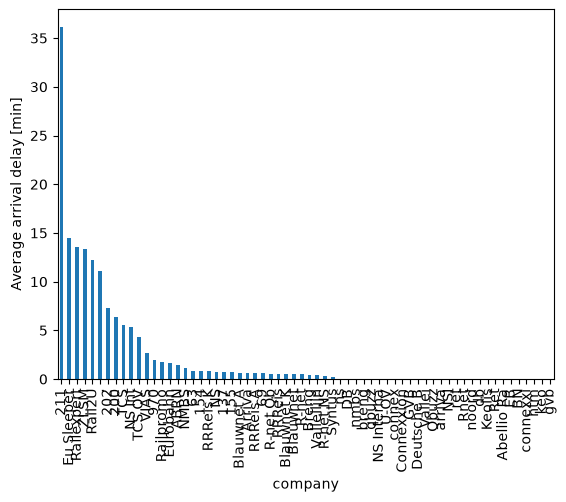

In [18]:
df = db.sql("""
SELECT "Service:Company" AS company, AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
  AND NOT COALESCE("Stop:Arrival cancelled", false)
GROUP BY company
ORDER BY avg_arrival_delay DESC
""").df()

df.plot.bar(
    x="company",
    y="avg_arrival_delay",
    legend=False,
    ylabel="Average arrival delay [min]",
)

How many services were disrupted in different years? Make a line plot.

<Axes: xlabel='year', ylabel='Number of disruptions'>

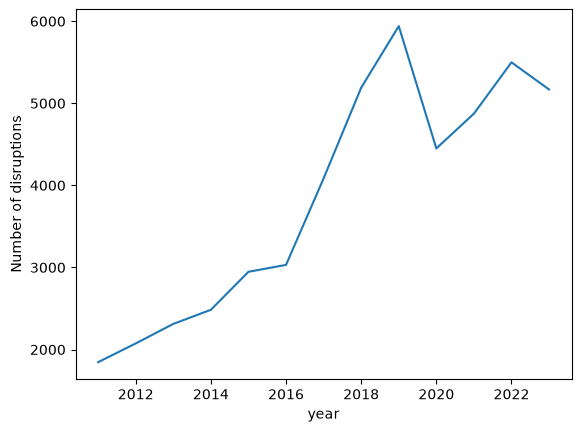

In [19]:
df = db.sql("""
SELECT YEAR(start_time) AS year, COUNT(*) AS num_disruptions
FROM pg.disruptions
GROUP BY year
ORDER BY year
""").df()

df.plot.line(
    x="year", y="num_disruptions", legend=False, ylabel="Number of disruptions"
)

What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.

<Axes: xlabel='year'>

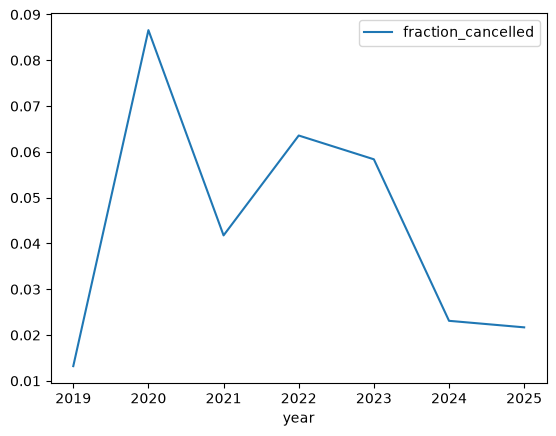

In [26]:
df = db.sql("""
SELECT YEAR("Service:Date") AS year, AVG("Service:Completely cancelled"::INT) AS fraction_cancelled
FROM (SELECT DISTINCT "Service:RDT-ID", "Service:Date", "Service:Completely cancelled" FROM services)
GROUP BY year
ORDER BY year
""").df()

df.plot.line(x="year", y="fraction_cancelled")

8. Currently, services table does not provide information about service lengths, neither between pairs of stations nor for the end-to-end service. Prepare this information:
Note that each service has the same Service:RDT-ID, and stations can be ordered by Stop:Departure time, with the last one being NULL. Using window functions, specifically LAG() or LEAD(), you can get next row. This example may also be useful.
Create table station_connections, with columns Service:RDT-ID, start_station_code and end_station_code (pair of stations on a route), and distance between them. Note that you should deduplicate the data on station codes, so that every station pair appears only once. Create temporary tables, use a subquery, or any other similar techniques if necessary.

In [21]:
db.sql("""
CREATE OR REPLACE TABLE station_connections AS
WITH pairs AS (
    SELECT
        "Service:RDT-ID",
        "Stop:Station code" AS start_station_code,
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID" ORDER BY "Stop:Departure time"
        ) AS end_station_code
    FROM services
)
SELECT DISTINCT ON (p.start_station_code, p.end_station_code)
    p."Service:RDT-ID", p.start_station_code, p.end_station_code, d.distance
FROM pairs AS p
JOIN distances_long AS d
    ON d.station = p.start_station_code AND d.other_station = p.end_station_code
""")

db.sql("FROM station_connections LIMIT 5")

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│         739000 │ ALMP               │ ALM              │        2 │
│         739486 │ RS                 │ OW               │       11 │
│         739486 │ NMD                │ NMGO             │        2 │
│         739586 │ ALMO               │ LLS              │       16 │
│         739693 │ IJT                │ SK               │        3 │
└────────────────┴────────────────────┴──────────────────┴──────────┘

What is the largest distance between a pair of stations?

In [22]:
db.sql("""
FROM station_connections
ORDER BY distance DESC
LIMIT 1
""")

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│        7123093 │ STV                │ VS               │      421 │
└────────────────┴────────────────────┴──────────────────┴──────────┘

Plot a histogram of inter-station distances run by trains.

<Axes: ylabel='Frequency'>

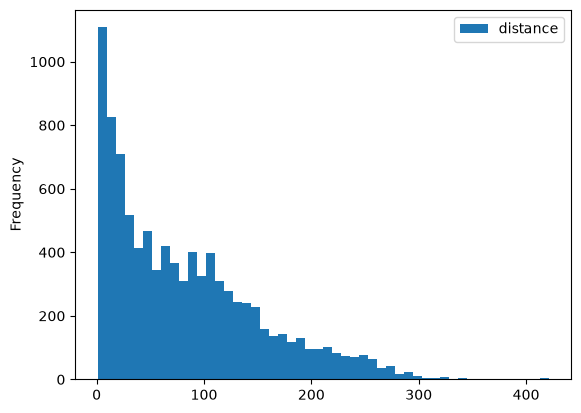

In [27]:
df = db.sql("SELECT distance FROM station_connections").df()

df.plot.hist(bins=50)